# Approach Risk 1.2 – Altitude Forecasting Pipeline

LFPG 09L: PostgreSQL → SQL → модели → MLflow. Реальный запуск на локальных данных 2025 года

## Задача и протокол

Прогнозируем последующую наблюдаемую высоту через 27–33 секунды. Физический baseline продолжает текущую вертикальную скорость; модели учат поправку. Девять train-дней, три validation-дня и три test-дня перенесены из 1.1. Каждый заход имеет равный вес. Scaler обучается на train; параметры моделей и early stopping выбираются по validation

In [1]:
# Загружаем сохраненные результаты без повторного обучения
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
display(pd.read_csv(root / "reports/split_inventory.csv"))

,season,split,rows,events
0,autumn,test,1074,14
1,autumn,train,3401,48
2,autumn,validation,1088,14
3,spring,test,366,24
4,spring,train,5315,282
5,spring,validation,1694,88
6,summer,test,484,17
7,summer,train,1999,54
8,summer,validation,510,12


## PostgreSQL и качество

Первая загрузка: 15 931 строка. Повторная: ноль новых строк. Извлечение сохранило все значения. Ключ наблюдения: airport + event_id + origin_time. SQL JOIN присоединяет фиксированный split дня; CTE считает ошибки с равным вкладом заходов

In [2]:
# Показываем состав данных из SQL и проверку физических соотношений
display(pd.read_csv(root / "reports/sql/01.csv").query("airport == 'LFPG'"))
display(pd.read_csv(root / "reports/sql/07.csv").query("airport == 'LFPG'"))

,airport,season,split,pairs,events
18,LFPG,autumn,test,1074,14
19,LFPG,autumn,train,3401,48
20,LFPG,autumn,validation,1088,14
21,LFPG,spring,test,366,24
22,LFPG,spring,train,5315,282
23,LFPG,spring,validation,1694,88
24,LFPG,summer,test,484,17
25,LFPG,summer,train,1999,54
26,LFPG,summer,validation,510,12


,airport,horizon_difference_s,baseline_difference_ft,residual_difference_ft
2,LFPG,0.0,0.0,0.0


## Структура данных и соединение

`study_days` содержит одну запись на аэропорт и день; `examples` – пары наблюдений. Первичный ключ пары: airport + event_id + origin_time. Внешний ключ связывает ее с днем. JOIN по airport и day переносит фиксированный split. Проверяем отдельно потери строк и множественные соответствия. Загрузка через временную таблицу и COPY выполняется одной транзакцией; конфликт данных или ошибка итоговой сверки отменяют изменения

```sql
SELECT e.event_id, e.origin_time, d.season, d.split
FROM altitude.examples e
JOIN altitude.study_days d USING (airport, day);
```

In [3]:
# Показываем проверку соединения и размеры выборок
display(pd.read_csv(root / "reports/sql/join_01.csv"))
display(pd.read_csv(root / "reports/sql/join_03.csv"))

,source_rows,joined_rows,unmatched_rows,nonunique_matches
0,15931,15931,0,0


,split,pairs,events,days
0,test,1924,55,3
1,train,10715,384,9
2,validation,3292,114,3


## Признаки и доступность во времени

Определения сверены с causal_features в scripts/lfpg_training.py и research/lfpg-seasonal-learning/scripts/prepare_examples.py исходного проекта 1.1

| Признак | Смысл | Единицы | Источник и доступность |
| --- | --- | --- | --- |
| height_ft | Высота с поправкой QNH над высотой аэродрома | ft | Текущая барометрическая высота, QNH на момент прогноза, высота аэродрома |
| vertical_rate_fps | Барометрическая вертикальная скорость с фактором QNH | ft/s | Текущее сообщение; геометрическая скорость исключена |
| past_height_rate_fps | Изменение барометрической высоты за предшествующий интервал с фактором текущего QNH | ft/s | Текущая и последняя подходящая прошлая точка |
| speed_knots | Путевая скорость | kt | Текущее наблюдение; это не приборная скорость |
| distance_m | Расстояние до порога | m | Текущее положение и геометрия полосы |
| lateral_m | Поперечное отклонение от оси | m | Текущее положение и геометрия полосы |
| heading_error_deg | Разница путевого угла и направления полосы в диапазоне [-180, 180) | градусы | Текущий track и геометрия; это не курс носа самолета |
| past_gap_s | Интервал до прошлой точки | s | История 5–30 секунд |
| horizon_s | Интервал до выбранного будущего наблюдения | s | Ретроспективный выбор цели, 27–33 секунды |

QNH применяется как исследовательское преобразование барометрической высоты; height_ft не является радиовысотой. Причинность восьми текущих/исторических признаков относится к построению примеров и предполагаемой доступности METAR. Сохраненный Parquet сам по себе не доказывает историческое время публикации METAR

horizon_s входит также в физический baseline. Строгий онлайн-прогноз на 30 секунд требует отдельного определения цели и эксперимента. Простая замена всех значений горизонта на 30 в этих примерах не повторяет исходную постановку

## Взвешенная предобработка

Для захода с n_i парами вес каждой пары пропорционален 1/n_i. Среднее и дисперсия StandardScaler вычисляются с этими весами только по train. Преобразование z = (x − mu_train) / sigma_train применяется к validation и test без обновления параметров. Это выравнивает вклад заходов, но не дней и сезонов

Проверка ниже отдельно вычисляет взвешенные моменты, сверяет сохраненный scaler MLP и проверяет неизменность параметров после transform. Повторное обучение моделей и новый выбор параметров не выполняются

{
  "weighted_mean_matches": true,
  "weighted_variance_matches": true,
  "weighted_scaled_mean_zero": true,
  "weighted_scaled_variance_one": true,
  "saved_mlp_mean_matches": true,
  "saved_mlp_scale_matches": true,
  "transform_preserves_parameters": true
}


,feature,weighted_mean,weighted_std,row_mean
0,height_ft,1619.551462,517.323098,1547.025113
1,vertical_rate_fps,-15.097293,3.096584,-14.704520
2,past_height_rate_fps,-15.056652,3.074631,-14.670268
3,speed_knots,166.403892,20.852755,162.960616
4,distance_m,9097.657767,2924.327564,8727.730447
5,lateral_m,-0.045046,8.074181,-0.125872
6,heading_error_deg,-0.078675,0.394095,-0.070500
7,past_gap_s,7.247594,1.998384,6.897983
8,horizon_s,29.985917,1.514704,29.981100


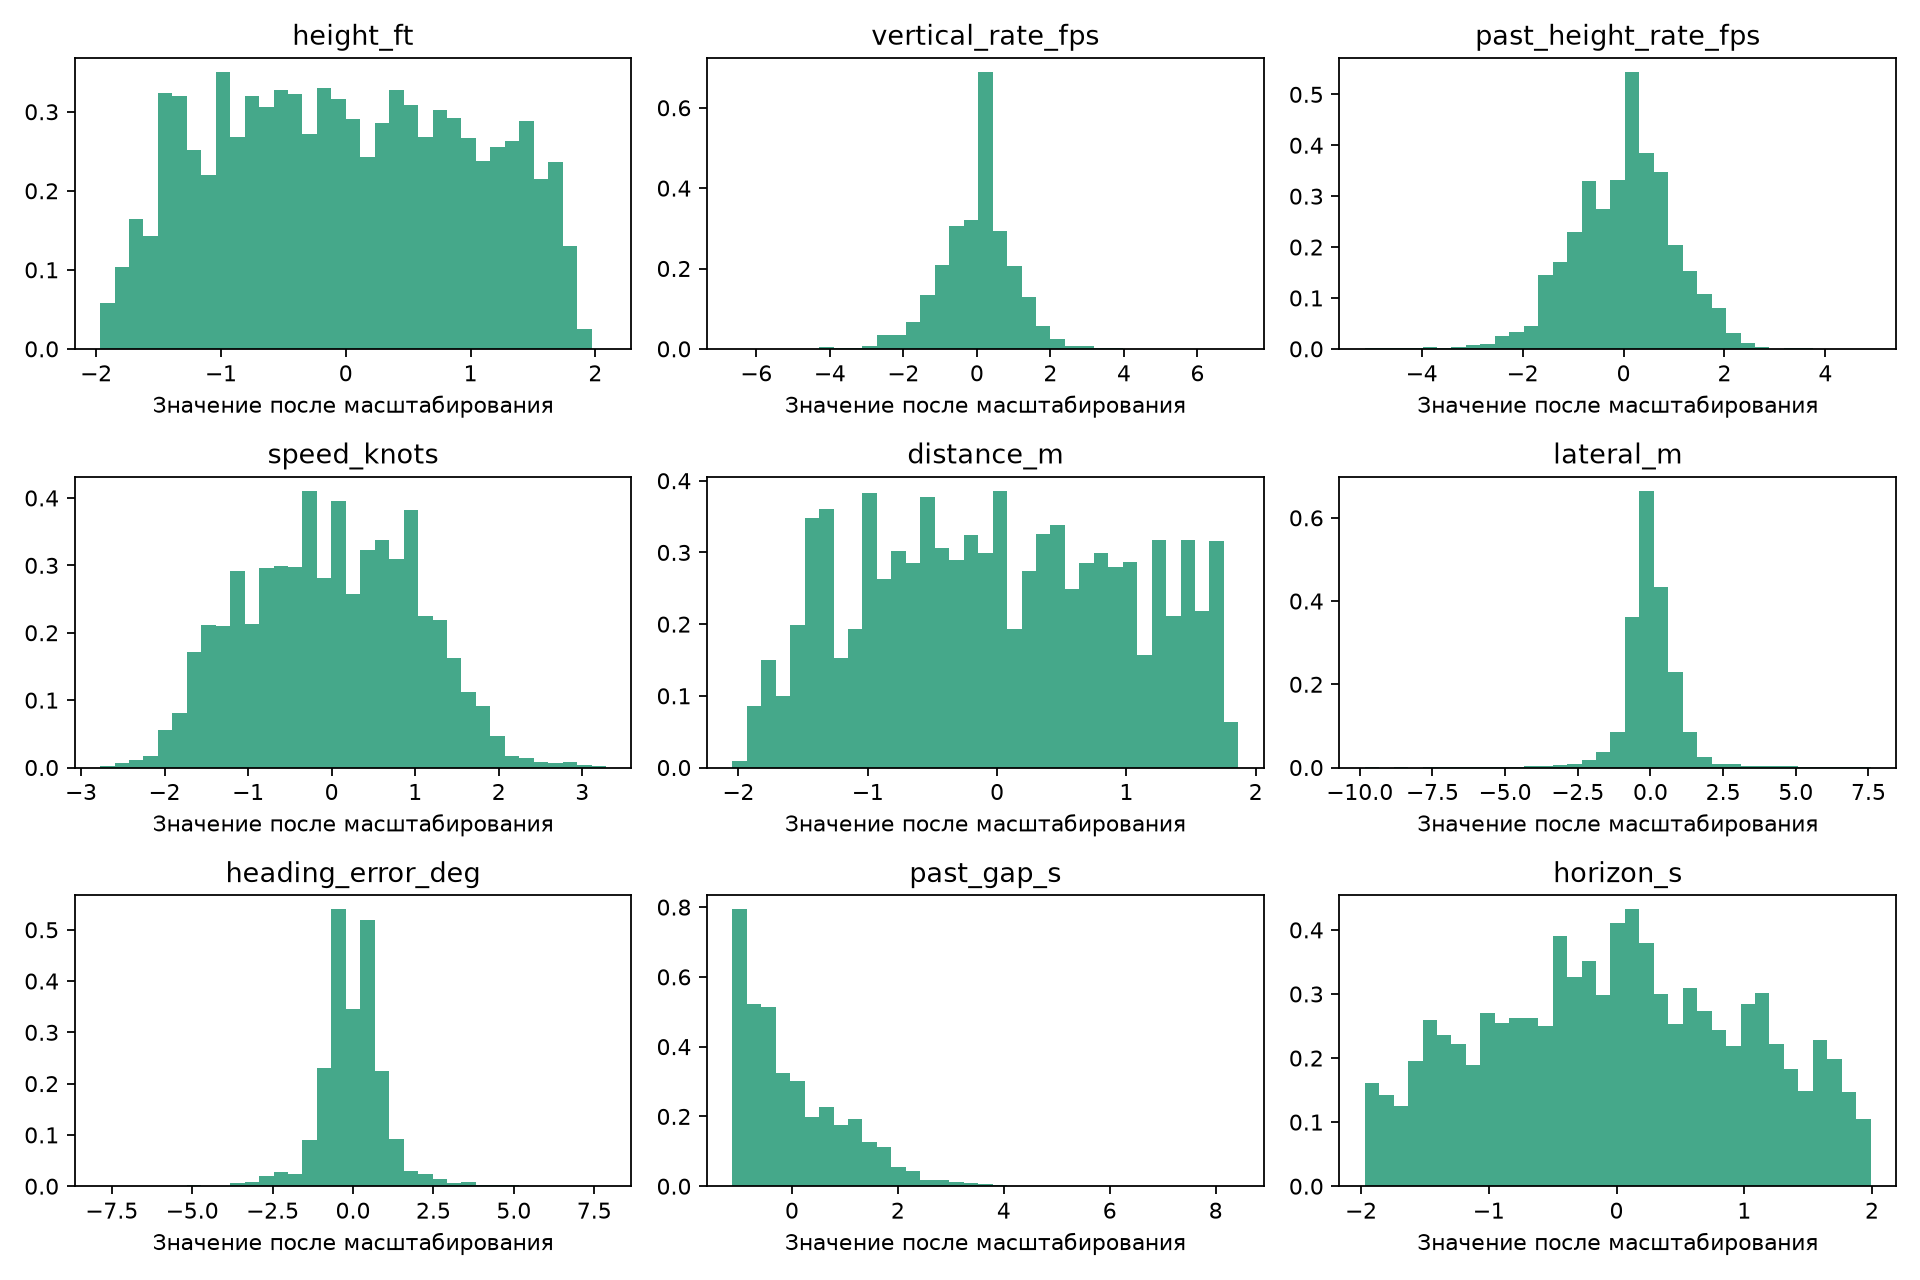

In [4]:
# Проверяем предобработку и показываем параметры обучающей выборки
import sys, json
sys.path.insert(0, str(root / "scripts"))
from review_preprocessing import run as review_preprocessing
review_preprocessing()
display(pd.read_csv(root / "reports/scaler_train.csv"))
display(Image(filename=str(root / "reports/scaled_train_features.png")))

Гистограммы используют только train и веса заходов. StandardScaler меняет масштаб, но не делает распределения нормальными. Наличие нескольких групп на графиках требует отдельного анализа структуры выборки; по этим графикам не вводились новые правила удаления наблюдений

## Усреднение ошибки по заходам

GROUP BY сначала вычисляет MAE каждого захода; CTE хранит промежуточный результат в пределах запроса. Затем ошибки усредняются между заходами. При усреднении по строкам вклад захода пропорционален числу пар. На тесте baseline: 49.35 ft по заходам и 51.58 ft по строкам. Количество пар зависит от плотности и пригодности наблюдений, поэтому не равно длительности захода

,airport,split,events,pairs,event_macro_mae_ft,row_mae_ft,min_pairs,median_pairs,max_pairs,pairs_mae_correlation
0,LFPG,test,55,1924,49.348959,51.575738,8,21.0,97,0.119039
1,LFPG,train,384,10715,57.733716,55.591887,7,20.0,96,-0.100664
2,LFPG,validation,114,3292,54.290466,50.220412,13,20.0,98,-0.179115


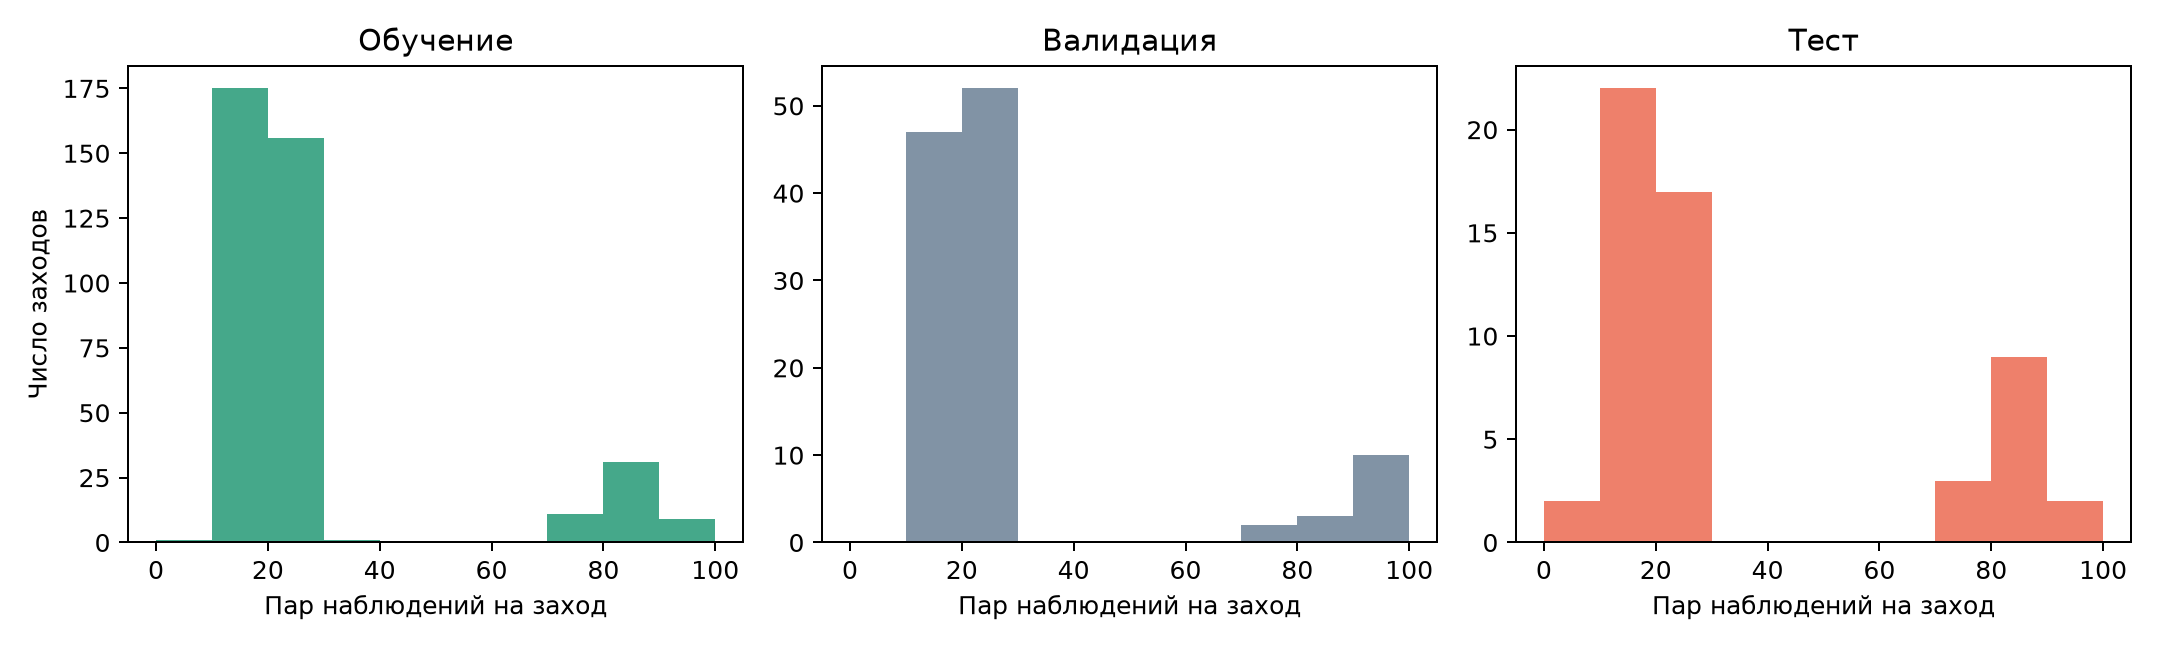

In [5]:
# Показываем независимый SQL-расчет и распределение числа пар
display(pd.read_csv(root / "reports/sql/event_mae_01.csv"))
display(Image(filename=str(root / "reports/event_pair_distribution.png")))

## Итоговое сравнение

Test содержит 55 заходов. MAE сначала усредняется внутри захода, затем между заходами. RMSE – квадратный корень из среднего по заходам MSE. Все варианты зафиксированы до вычисления test-метрик; новый подбор по test не проводится

,model,macro_mae_ft,macro_rmse_ft,run_id
0,Constant vertical rate,49.348959,67.995818,af81171321ba41da902589bff85a3858
1,Ridge,20.033286,25.796078,58f9e5e9015e4478b4c9631b4aa613d0
2,Polynomial Ridge,17.163963,22.244615,54224c6909c1451aa7c24c45feaa2dc5
3,PyTorch MLP,18.862559,24.466738,e1e47564e32845768281b8f447e7e21b


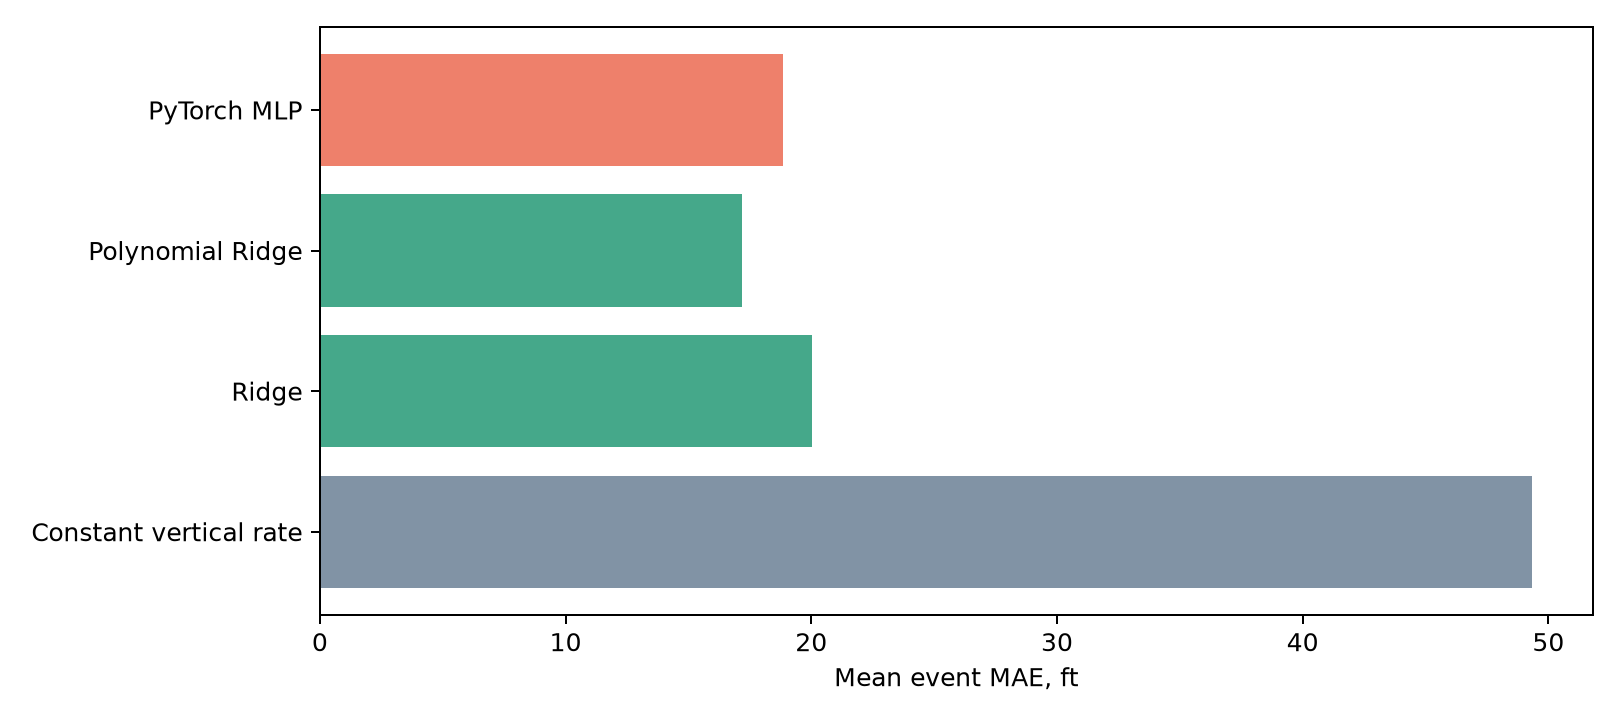

In [6]:
# Показываем измеренные метрики и график сравнения
display(pd.read_csv(root / "reports/model_metrics.csv"))
display(Image(filename=str(root / "reports/model_comparison.png")))

## PyTorch

MLP с двумя скрытыми слоями и ReLU учит residual. DataLoader перемешивает только train. Взвешенный MSE сохраняет равный вклад заходов. Adam, seed 20261014, ширина 16 или 32, до 300 эпох; остановка после 30 эпох без улучшения validation MAE

,model,parameter,validation_macro_mae_ft
0,Ridge,1,17.420799
1,Ridge,10,17.684009
2,Ridge,100,19.099109
3,Polynomial Ridge,1,16.990514
4,Polynomial Ridge,10,17.304185
5,Polynomial Ridge,100,18.478840
6,PyTorch MLP,16,17.064349
7,PyTorch MLP,32,17.105717


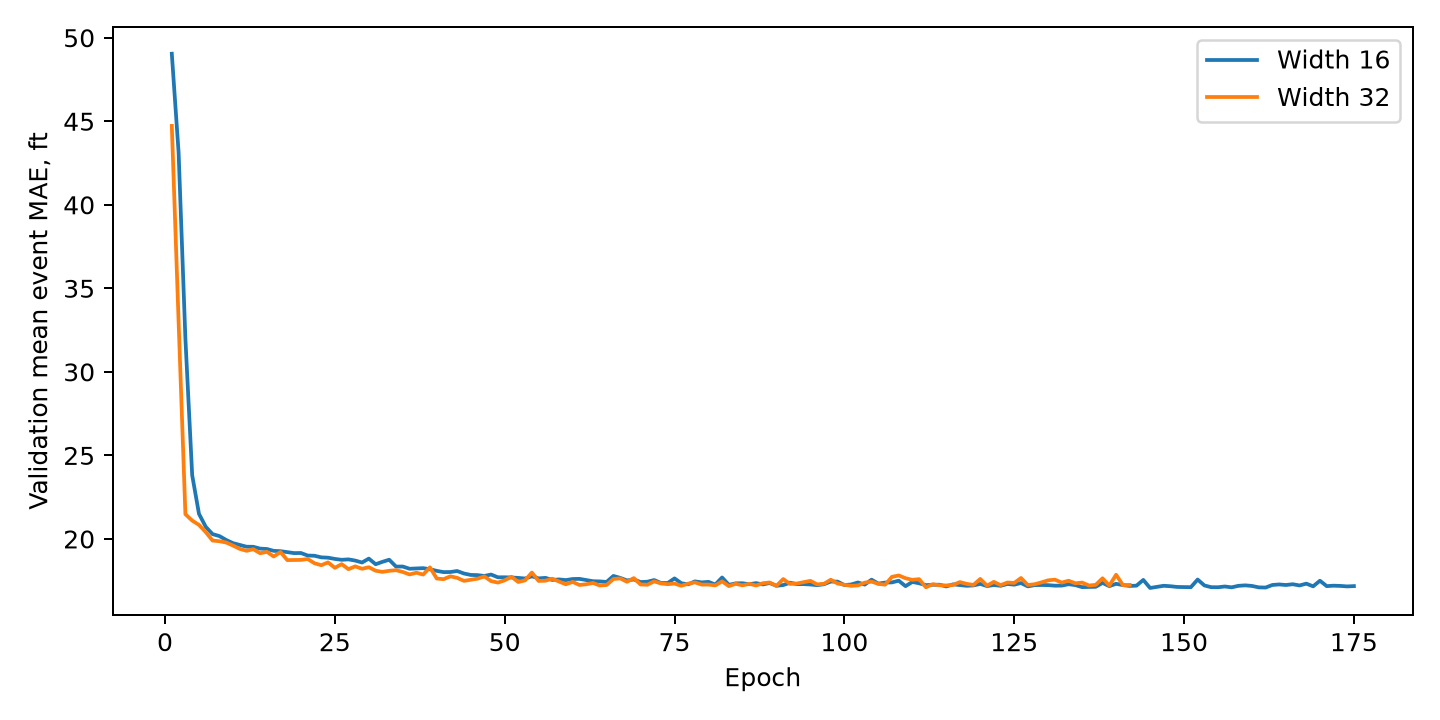

In [7]:
# Проверяем выбор параметров по валидации без обращения к тестовой выборке
display(pd.read_csv(root / "reports/validation_search.csv"))
display(Image(filename=str(root / "reports/mlp_validation.png")))

## Анализ ошибок фиксированных моделей

Использованы сохраненная MLP из 1.2 и классические pooled-модели из 1.1. Классические модели первого запуска 1.2 не были сохранены. Для моделей 1.1 проверены набор признаков, выбранные alpha и совпадение агрегатных MAE/RMSE с результатами 1.2; совпадение агрегатов не доказывает идентичность каждого отдельного предсказания первого запуска. Хеши артефактов зафиксированы. Обучение, выбор параметров и корректировка моделей не выполнялись

Bias определяется как прогноз минус наблюдаемая высота: положительное значение означает завышение. Средняя bias и RMSE сохраняют равный вклад заходов. P90 относится к распределению MAE отдельных заходов, не к ошибкам отдельных точек

,model,season,events,macro_mae_ft,macro_bias_ft,macro_rmse_ft,median_event_mae_ft,p90_event_mae_ft
0,Constant vertical rate,autumn,14,56.664255,-29.119006,76.606941,55.638022,76.752993
1,Constant vertical rate,spring,24,44.433501,-11.996732,60.279697,47.274639,71.046688
2,Constant vertical rate,summer,17,50.264067,-18.828433,70.677639,42.796957,68.077298
3,Polynomial Ridge,autumn,14,16.320013,-2.167317,21.589166,16.599648,23.299141
4,Polynomial Ridge,spring,24,17.927073,-2.971948,23.110637,18.231667,23.011126
5,Polynomial Ridge,summer,17,16.781650,9.217537,21.518163,15.481364,24.060127
6,PyTorch MLP,autumn,14,16.749520,-3.072988,21.977988,16.891931,22.457414
7,PyTorch MLP,spring,24,20.467805,-11.588074,26.003793,19.920529,28.488456
8,PyTorch MLP,summer,17,18.336479,10.623942,24.172163,16.241087,25.173845
9,Ridge,autumn,14,16.091458,-3.068172,20.686032,16.100906,20.445882


,model,reference,events,mean_delta_mae_ft,median_delta_mae_ft,better_events,worse_events
0,Ridge,Constant vertical rate,55,-29.315673,-28.903008,48,7
1,Ridge,Polynomial Ridge,55,2.869323,1.389592,14,41
2,Polynomial Ridge,Constant vertical rate,55,-32.184996,-30.821813,52,3
3,PyTorch MLP,Constant vertical rate,55,-30.486400,-27.067501,51,4
4,PyTorch MLP,Polynomial Ridge,55,1.698596,1.086284,13,42


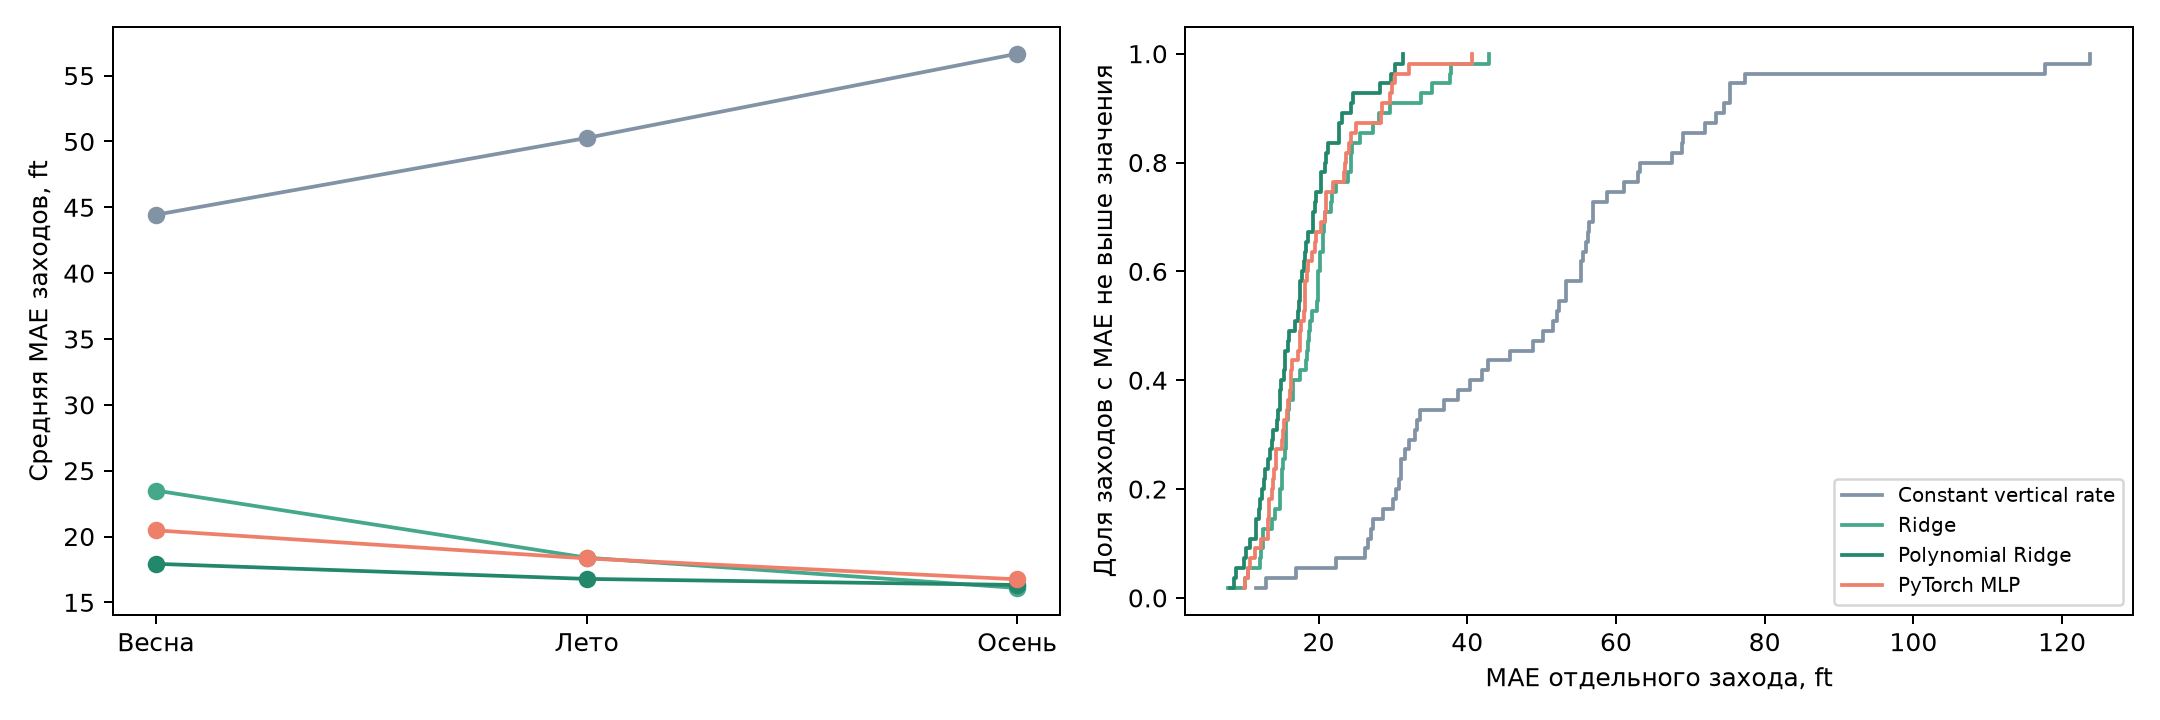

In [8]:
# Показываем сезонные ошибки и парное сравнение одних и тех же заходов
display(pd.read_csv(root / "reports/errors_by_season.csv"))
display(pd.read_csv(root / "reports/paired_event_errors.csv"))
display(Image(filename=str(root / "reports/error_analysis.png")))

Polynomial Ridge улучшила baseline на 52 из 55 заходов, MLP – на 51. MLP уступила Polynomial Ridge на 42 заходах и улучшила ее на 13; средняя разница MAE составила +1.70 ft. Осенью Ridge имеет меньшую среднюю MAE, чем Polynomial Ridge и MLP. Общее превосходство Polynomial Ridge не означает превосходства на каждом заходе или в каждой подгруппе

Летом средняя bias Polynomial Ridge равна +9.22 ft, MLP +10.62 ft; весной соответственно −2.97 и −11.59 ft, осенью −2.17 и −3.07 ft. Каждому сезону соответствует один тестовый день. Сезон, конкретный день и состав заходов смешаны: эти наблюдения не доказывают причинный сезонный эффект. Доверительные интервалы и статистическая значимость пока не оценены. Точки одного захода зависимы, а борта могут повторяться между днями; независимый bootstrap строк не подходит для обоснования выводов

## Неопределенность парной разницы ошибок

В тесте 55 заходов, 53 борта и три дня. Два борта встречаются в нескольких днях. Выполнен парный кластерный bootstrap по icao24: выбираем 53 борта с возвращением, сохраняем все заходы каждого выбранного борта вместе и считаем среднюю разницу MAE моделей по заходам. Число заходов в повторе может меняться. 10 000 повторов, seed 20261014; границы – процентили 2.5% и 97.5%

Отрицательная разница означает меньшую ошибку первой модели. Это исследовательские интервалы условно на наблюдаемых днях, а не оценка переноса на новые дни. Общая зависимость внутри дня не моделируется. При трех тестовых днях надежную неопределенность по дням установить нельзя

,day,season,events,aircraft
0,2025-03-17,spring,24,24
1,2025-08-25,summer,17,17
2,2025-11-04,autumn,14,14


,model,reference,mean_delta_mae_ft,lower_95_ft,upper_95_ft,clusters,events,repetitions,seed
0,Polynomial Ridge,Constant vertical rate,-32.184996,-37.966354,-26.625747,53,55,10000,20261014
1,PyTorch MLP,Constant vertical rate,-30.486400,-36.402059,-24.796655,53,55,10000,20261014
2,PyTorch MLP,Polynomial Ridge,1.698596,0.829461,2.647637,53,55,10000,20261014
3,Ridge,Polynomial Ridge,2.869323,1.435386,4.523258,53,55,10000,20261014


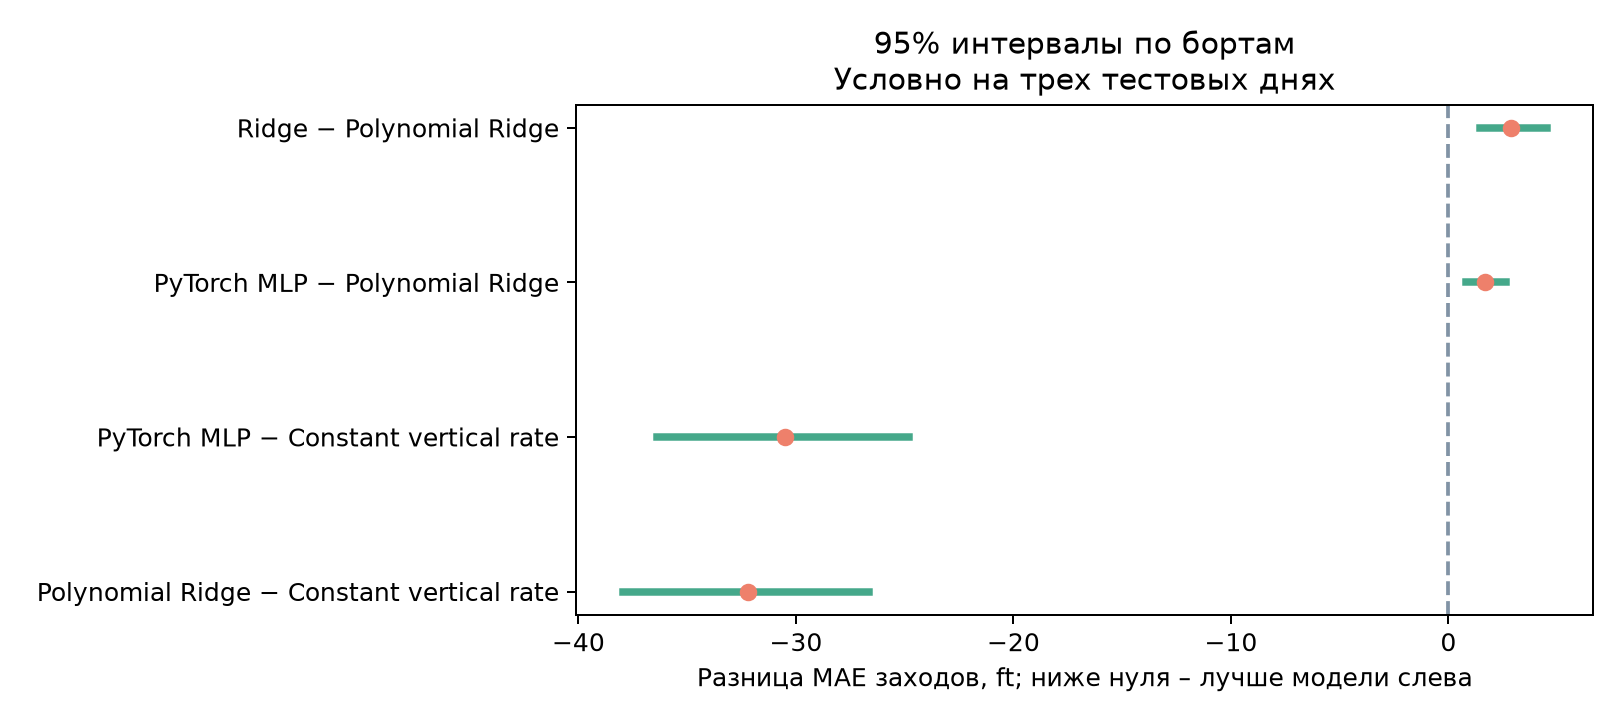

In [9]:
# Показываем состав кластеров и интервалы парных разниц
display(pd.read_csv(root / "reports/test_cluster_inventory.csv"))
display(pd.read_csv(root / "reports/paired_uncertainty.csv"))
display(Image(filename=str(root / "reports/paired_uncertainty.png")))

Средняя разница MLP − Polynomial Ridge равна +1.70 ft, интервал +0.83…+2.65 ft. В рамках выбранной схемы повторной выборки преимущество Polynomial Ridge сохраняется. Это не подтверждающий тест общей научной гипотезы: сравнения исследовательские, выполнены после просмотра test, поправка на множественные сравнения не применялась. Не учтены неопределенность обучающей выборки и вариативность seed MLP. Для обобщения нужны дополнительные независимые дни и заранее фиксированная схема оценки

## PyTorch: устройство и восстановление модели

Выбранная MLP: 9 → 16 → 16 → 1, ReLU между линейными слоями, 449 параметров. TensorDataset хранит тройки признаков, residual и веса. DataLoader перемешивает train и формирует пакеты до 256 примеров, без дополнительных процессов

Цель обучения – residual / s, где s = 79.87898 ft – взвешенное среднеквадратическое значение residual на train, без вычитания среднего. Это нормировка масштаба цели, не StandardScaler для цели. Прогноз высоты равен baseline + s × выход сети

Функция потерь пакета: mean(w × (prediction − target)^2). Веса нормированы по всей обучающей выборке, поэтому при равномерной выборке строк градиент соответствует взвешенной цели в среднем. Малый последний пакет и последовательное обновление параметров не эквивалентны одному полному градиентному шагу

zero_grad очищает градиенты, backward вычисляет производные, Adam обновляет веса (learning rate 0.001, weight decay 0.0001). Для validation выполняются eval и no_grad. train_weighted_mse в истории усредняет потери пакетов, вычисленные при меняющихся параметрах внутри эпохи; это не точная train-loss финальной модели эпохи. Ее нельзя напрямую сопоставлять с validation MAE в ft

Ширина и лучшая эпоха выбираются по validation. Test не участвует в остановке. Из двух ширин выбрана 16; лучшие веса относятся к эпохе 145, остановка – 175. Один seed не характеризует вариативность нейросетевого обучения

In [10]:
# Показываем выбор эпохи и проверку восстановленных моделей
display(pd.read_csv(root / "reports/mlp_selection.csv"))
display(pd.read_csv(root / "reports/artifact_verification.csv"))

,width,best_epoch,stopped_epoch,best_validation_mae_ft,selected
0,16,145,175,17.064349,True
1,32,112,142,17.105717,False


,model,origin,artifact,sha256,restore_exact,validation_mae_ft,macro_mae_ft,macro_rmse_ft
0,Ridge,imported_from_1.1,ridge.joblib,e26987be55baa23c5ffcfc6e04cf76f00e63eee85c9c85...,True,17.420799,20.033286,25.796078
1,Polynomial Ridge,imported_from_1.1,polynomial_ridge.joblib,53b794a356f7cd8db647e95475b74de44eab8d61958353...,True,16.990514,17.163963,22.244615
2,PyTorch MLP,trained_in_1.2,mlp.pt,5faace805f58aa631e0bbfba06149145df238c6e7c907a...,True,17.064349,18.862559,24.466738


Артефакт MLP содержит state_dict, ширину, порядок признаков, средние и масштабы признаков, масштаб residual. Он пригоден для восстановления прогнозов, но не для точного продолжения обучения: состояние optimizer и генератора случайных чисел не сохранено

Классические pipeline сохранены в 1.2 как импорт из 1.1. Для них проверены validation-метрики, итоговые MAE/RMSE и неизменность прогнозов после сохранения. Это не восстановленные артефакты первого запуска 1.2. Будущие запуски train.py сохраняют выбранные pipeline непосредственно при обучении и добавляют их в MLflow

## Интерпретация и ограничения

MLP улучшила физический baseline, но уступила Polynomial Ridge на этом тесте. Это результат ограниченного эксперимента, без доказательства общего превосходства модели. Данные относятся к одной полосе и отобранным погожим дням. Между split повторяются борта. Фактический горизонт известен ретроспективно и входит в признаки. Строгий онлайн-горизонт 30 секунд, go-around и эксплуатационная безопасность не проверены

## Итог LFPG

Физический baseline улучшен обучаемыми поправками. Polynomial Ridge имеет меньшую среднюю MAE, чем MLP на текущем тесте. Условный bootstrap по бортам поддерживает это направление разницы, но не характеризует перенос на новые дни. Воспроизведение сохраненных прогнозов отделено от повторного обучения. Для строгого онлайн-горизонта 30 секунд требуется новая заранее определенная постановка; текущий ретроспективный горизонт не заменяется молча